In [1]:
print("Importing...")
%load_ext autoreload
%autoreload 2
import regional_mom6 as rm6 # type: ignore
from regional_mom6.utils import ap2ep, ep2ap # type: ignore
import xarray as xr
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import numpy as np


Importing...


In [11]:
hgrid = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/regional-mom6-archives/mom_input/2n3b.nwa-three-boundary-new-regridding/hgrid.nc")
coords = rm6.regridding.coords(hgrid, "north", "segment_002")
hgrid

2025-01-02 14:16:30,902 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary q/u/v points


<xarray.Dataset> Size: 111MB
Dimensions:   (nyp: 1561, nxp: 1481, ny: 1560, nx: 1480)
Dimensions without coordinates: nyp, nxp, ny, nx
Data variables:
    tile      |S255 255B ...
    y         (nyp, nxp) float64 18MB ...
    x         (nyp, nxp) float64 18MB ...
    dy        (ny, nxp) float64 18MB ...
    dx        (nyp, nx) float64 18MB ...
    area      (ny, nx) float64 18MB ...
    angle_dx  (nyp, nxp) float64 18MB ...
Attributes:
    file_name:    ocean_hgrid.nc
    Description:  MOM6 NCAR NWA12
    Author:       Fred Castruccio (fredc@ucar.edu)
    Created:      2024-04-18T08:39:49.607481
    type:         MOM6 supergrid file

In [33]:
forcing_seg_3_gfdl  = xr.open_dataset("/glade/work/gmarques/Projects/NWA12/boundary_conditions/uv_003_1993.nc")
forcing_seg_3  = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/gfdl_copy.2.n3b/forcing_obc_segment_003.nc")
forcing_seg_2  = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/gfdl_copy.2.n3b/forcing_obc_segment_002.nc")

initial_condition_gfdl  = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/gfdl_copy.2.n3b/save_backups/init_vel.nc")
inital_condition  = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/gfdl_copy.2.n3b/save_backups/init_vel.nc")
forcing_seg_2

<xarray.Dataset> Size: 114MB
Dimensions:              (time: 32, nz_segment_002_u: 50, ny_segment_002: 1,
                          nx_segment_002: 1481, nz_segment_002_v: 50,
                          nz_segment_002_salt: 50, nz_segment_002_temp: 50,
                          nz_salt_segment_002: 50, nz_temp_segment_002: 50,
                          nz_u_segment_002: 50, nz_v_segment_002: 50, depth: 50)
Coordinates:
  * depth                (depth) float32 200B 0.494 1.541 ... 5.728e+03
  * time                 (time) object 256B 1993-01-01 00:00:00 ... 1993-02-0...
    lon_segment_002      (nx_segment_002) float64 12kB ...
    lat_segment_002      (nx_segment_002) float64 12kB ...
  * nz_segment_002_salt  (nz_segment_002_salt) int32 200B 0 1 2 3 ... 47 48 49
  * nz_segment_002_temp  (nz_segment_002_temp) int32 200B 0 1 2 3 ... 47 48 49
  * nz_segment_002_u     (nz_segment_002_u) int32 200B 0 1 2 3 4 ... 46 47 48 49
  * nz_segment_002_v     (nz_segment_002_v) int32 200B 0 1 2 3 4 ... 46 47 48 49
  * nx_segment_002       (nx_segment_002) int32 6kB 0 1 2 3 ... 1478 1479 1480
  * ny_segment_002       (ny_segment_002) int32 4B 0
Dimensions without coordinates: nz_salt_segment_002, nz_temp_segment_002,
                                nz_u_segment_002, nz_v_segment_002
Data variables:
    u_segment_002        (time, nz_segment_002_u, ny_segment_002, nx_segment_002) float64 19MB ...
    v_segment_002        (time, nz_segment_002_v, ny_segment_002, nx_segment_002) float64 19MB ...
    eta_segment_002      (time, ny_segment_002, nx_segment_002) float64 379kB ...
    salt_segment_002     (time, nz_segment_002_salt, ny_segment_002, nx_segment_002) float64 19MB ...
    temp_segment_002     (time, nz_segment_002_temp, ny_segment_002, nx_segment_002) float64 19MB ...
    dz_salt_segment_002  (time, nz_salt_segment_002, ny_segment_002, nx_segment_002) float32 9MB ...
    dz_temp_segment_002  (time, nz_temp_segment_002, ny_segment_002, nx_segment_002) float32 9MB ...
    dz_u_segment_002     (time, nz_u_segment_002, ny_segment_002, nx_segment_002) float32 9MB ...
    dz_v_segment_002     (time, nz_v_segment_002, ny_segment_002, nx_segment_002) float32 9MB ...

In [37]:
forcing_seg_2.v_segment_002[0,0,0]

<xarray.DataArray 'v_segment_002' ()> Size: 8B
[1 values with dtype=float64]
Coordinates:
    time              object 8B 1993-01-01 00:00:00
    lon_segment_002   float64 8B ...
    lat_segment_002   float64 8B ...
    nz_segment_002_v  int32 4B 0
    nx_segment_002    int32 4B 1
    ny_segment_002    int32 4B 0

In [38]:
vals = forcing_seg_2.v_segment_002[0,0,0,np.arange(1, 1481, 2)]
vals_gfdl = forcing_seg_3_gfdl.u_segment_003[0,0,np.arange(1, 1561, 2)]


740

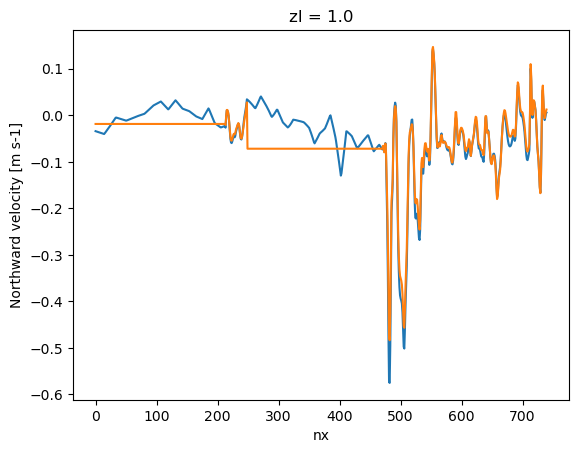

In [41]:
inital_condition.v[0,-1,:].plot()

plt.plot(vals.values)
#plt.plot(vals_gfdl.values)

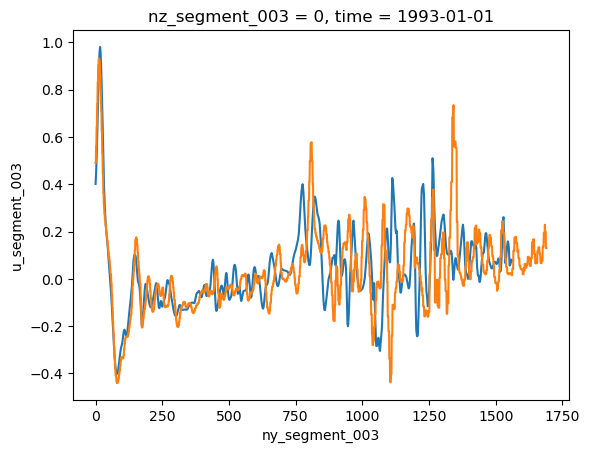

In [6]:
forcing_seg_3.u_segment_003[0][0].plot()
forcing_seg_3_gfdl.u_segment_003[0][0].plot()

In [7]:
bathy = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/angle_calc.1.2n3b/bathymetry.nc")


north_mask = rm6.regridding.get_boundary_mask(hgrid, bathy, "north", "segment_002")
south_mask = rm6.regridding.get_boundary_mask(hgrid, bathy, "south", "segment_001")
east_mask = rm6.regridding.get_boundary_mask(hgrid, bathy, "east", "segment_003")
new_east_mask = east_mask[ :, np.newaxis]

north_mask

2024-12-26 09:20:21,358 - regional_mom6.regridding.get_hgrid_arakawa_c_points - INFO - Getting t points..


2024-12-26 09:20:21,373 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary t-points
2024-12-26 09:20:21,373 - regional_mom6.regridding.get_hgrid_arakawa_c_points - INFO - Getting t points..
2024-12-26 09:20:21,384 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary q/u/v points
2024-12-26 09:20:21,570 - regional_mom6.regridding.get_hgrid_arakawa_c_points - INFO - Getting t points..
2024-12-26 09:20:21,584 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary t-points
2024-12-26 09:20:21,585 - regional_mom6.regridding.get_hgrid_arakawa_c_points - INFO - Getting t points..
2024-12-26 09:20:21,595 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary q/u/v points
2024-12-26 09:20:21,784 - regional_mom6.regridding.get_hgrid_arakawa_c_points - INFO - Getting t points..
2024-12-26 09:20:21,800 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary t-points
202

array([ 0., nan, nan, ...,  1.,  1.,  1.])

In [8]:
north_mask[930:1000]

array([nan, nan, nan, nan, nan, nan, nan, nan,  0.,  0.,  0.,  1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1.,  1.,  1.,  1.,  1.])

In [27]:
ind_to_upset = []
ind_to_upset.append(np.where(np.isnan(north_mask))[0][-1]+1)
ind_to_upset.append(np.where(np.isnan(north_mask))[0][-1]+2)
ind_to_upset.append(np.where(np.isnan(north_mask))[0][-1]+3)
ind_to_upset
upset_data = np.full(north_mask.shape,0)
upset_data[ind_to_upset] = 50
upset_data

array([0, 0, 0, ..., 0, 0, 0])

In [42]:
path = "/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/angle_calc.3.2n3b/"
adjusted_path = "/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/angle_calc.1.2n3b/adjusted_forcing/"
datasets = ["tz_segment_003.nc",
            "tz_segment_002.nc",
            "tz_segment_001.nc",
            "tu_segment_003.nc",
            "tu_segment_002.nc",
            "tu_segment_001.nc",
            "forcing_obc_segment_003.nc",
            "forcing_obc_segment_002.nc",
            "forcing_obc_segment_001.nc"]
tu_2 = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/tides_dev/outputs/given_angle/forcing/tu_segment_002.nc")
tu_1 = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/tides_dev/outputs/given_angle/forcing/tu_segment_001.nc")
tu_3 = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/tides_dev/outputs/given_angle/forcing/tu_segment_003.nc")
tz_2 = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/tides_dev/outputs/given_angle/forcing/tz_segment_002.nc")
tz_1 = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/tides_dev/outputs/given_angle/forcing/tz_segment_001.nc")
tz_3 = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/tides_dev/outputs/given_angle/forcing/tz_segment_003.nc")
f_1 = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/tides_dev/outputs/given_angle/forcing_obc_segment_001.nc")
f_2 = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/tides_dev/outputs/given_angle/forcing_obc_segment_002.nc")
f_3 = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/tides_dev/outputs/given_angle/forcing_obc_segment_003.nc")

encoding_tu_2 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_002": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_002": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tu_2 = rm6.regridding.generate_encoding(
    tu_2, encoding_tu_2, default_fill_value = 1.0e20
)
encoding_tz_2 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_002": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_002": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tz_2 = rm6.regridding.generate_encoding(
    tz_2, encoding_tz_2, default_fill_value = 1.0e20
)
encoding_dict_f_2 = {
    "time": {"dtype": "double"},
    f"nx_segment_002": {
        "dtype": "int32",
    },
    f"ny_segment_002": {
        "dtype": "int32",
    },
}
encoding_dict_f_2 = rm6.regridding.generate_encoding(
    f_2,
    encoding_dict_f_2,
    default_fill_value=1.0e20,
)

encoding_tu_3 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_003": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_003": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tu_3 = rm6.regridding.generate_encoding(
    tu_3, encoding_tu_3, default_fill_value = 1.0e20
)
encoding_tz_3 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_003": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_003": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tz_3 = rm6.regridding.generate_encoding(
    tz_3, encoding_tz_3, default_fill_value = 1.0e20
)
encoding_dict_f_3 = {
    "time": {"dtype": "double"},
    f"nx_segment_003": {
        "dtype": "int32",
    },
    f"ny_segment_003": {
        "dtype": "int32",
    },
}
encoding_dict_f_3 = rm6.regridding.generate_encoding(
    f_3,
    encoding_dict_f_3,
    default_fill_value=1.0e20,
)

encoding_tu_1 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_001": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_001": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tu_1 = rm6.regridding.generate_encoding(
    tu_1, encoding_tu_1, default_fill_value = 1.0e20
)
encoding_tz_1 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_001": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_001": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tz_1 = rm6.regridding.generate_encoding(
    tz_1, encoding_tz_1, default_fill_value = 1.0e20
)
encoding_dict_f_1 = {
    "time": {"dtype": "double"},
    f"nx_segment_001": {
        "dtype": "int32",
    },
    f"ny_segment_001": {
        "dtype": "int32",
    },
}
encoding_dict_f_1 = rm6.regridding.generate_encoding(
    f_1,
    encoding_dict_f_1,
    default_fill_value=1.0e20,
)

2024-12-26 08:47:48,205 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-26 08:47:48,205 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-26 08:47:48,206 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-26 08:47:48,206 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-26 08:47:48,207 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-26 08:47:48,207 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-26 08:47:48,208 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-26 08:47:48,208 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-26 08:47:48,209 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary


In [43]:
for ds_path in datasets:
    ds = xr.open_dataset(path+ds_path)
    for var in ds.data_vars.keys():
        if "003" in var:  
            ds[var] = ds[var].fillna(0)
            ds[var]=ds[var]*new_east_mask
        elif "002" in var:
            ds[var] = ds[var].fillna(0)
            ds[var]=ds[var]*north_mask
            
        elif "001" in var:
            ds[var] = ds[var].fillna(0)
            ds[var]=ds[var]*south_mask
    if "tz" in ds_path and "003" in ds_path:
        encoding_dict = encoding_tz_3
    elif "tu" in ds_path and "003" in ds_path:
        encoding_dict = encoding_tu_3
    elif "forcing" in ds_path and "003" in ds_path:
        encoding_dict = encoding_dict_f_3
    elif "tz" in ds_path and "002" in ds_path:
        encoding_dict = encoding_tz_2
    elif "tu" in ds_path and "002" in ds_path:
        encoding_dict = encoding_tu_2
    elif "forcing" in ds_path and "002" in ds_path:
        encoding_dict = encoding_dict_f_2
    elif "tz" in ds_path and "001" in ds_path:
        encoding_dict = encoding_tz_1
    elif "tu" in ds_path and "001" in ds_path:
        encoding_dict = encoding_tu_1
    elif "forcing" in ds_path and "001" in ds_path:
        encoding_dict = encoding_dict_f_1
    ds.to_netcdf(adjusted_path+ds_path, encoding=encoding_dict,
            unlimited_dims="time")

In [10]:
np.where(ocean_static_obc["wet"][-1].values==0)

(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
         13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
         26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
         39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
         52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
         65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
         78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
         91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
        104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
        117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
        130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
        143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
        156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
        169, 170, 171, 172, 173, 174, 175, 176, 177

<xarray.Dataset> Size: 65MB
Dimensions:       (xh: 740, yh: 780, time: 1, xq: 741, yq: 781)
Coordinates:
  * xh            (xh) float64 6kB -97.96 -97.88 -97.79 ... -36.54 -36.46 -36.38
  * yh            (yh) float64 6kB 5.243 5.326 5.409 5.492 ... 53.82 53.86 53.89
  * time          (time) object 8B 2003-01-01 00:00:00
  * xq            (xq) float64 6kB -98.0 -97.92 -97.83 ... -36.5 -36.42 -36.33
  * yq            (yq) float64 6kB 5.201 5.284 5.367 5.45 ... 53.84 53.87 53.91
Data variables: (12/28)
    areacello     (yh, xh) float32 2MB ...
    deptho        (yh, xh) float32 2MB ...
    Coriolis      (yq, xq) float32 2MB ...
    geolon        (yh, xh) float32 2MB ...
    geolat        (yh, xh) float32 2MB ...
    geolon_c      (yq, xq) float32 2MB ...
    ...            ...
    dyCu          (yh, xq) float32 2MB ...
    dxCv          (yq, xh) float32 2MB ...
    dyCv          (yq, xh) float32 2MB ...
    areacello_cu  (yh, xq) float32 2MB ...
    areacello_cv  (yq, xh) float32 2MB ...
    areacello_bu  (yq, xq) float32 2MB ...
Attributes:
    NumFilesInSet:  1
    title:          mom6-regional
    grid_type:      regular
    grid_tile:      N/A